In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

In [6]:
# Works whether the notebook is run from the project root or notebooks folder
if os.path.exists("data/raw/bank_data.csv"):
    DATA_PATH = "data/raw/bank_data.csv"
    IMAGE_DIR = "images"
elif os.path.exists("../data/raw/bank_data.csv"):
    DATA_PATH = "../data/raw/bank_data.csv"
    IMAGE_DIR = "../images"
else:
    raise FileNotFoundError(
        "bank_data.csv was not found. Keep it inside data/raw/."
    )

os.makedirs(IMAGE_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully!")
print("CSV location:", DATA_PATH)
print("Images will be saved in:", IMAGE_DIR)

Dataset loaded successfully!
CSV location: ../data/raw/bank_data.csv
Images will be saved in: ../images


In [7]:
df.head()

,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income,Tenure_Years,Monthly_Transactions,Branch_Visits,Last_Review_Date,Avg_Monthly_Balance
0,C1244,Mumbai,Current,Salaried,Branch,38,33000.0,2.2,27.0,2,2025-05-13,26500
1,C1103,Bengaluru,Current,Salaried,Net_Banking,23,41500.0,NaN,14.0,2,2025-08-17,44100
2,C1210,Lucknow,Savings,Self_Employed,Mobile_App,52,23500.0,1.0,31.0,1,2026-02-24,6400
3,C1179,Bengaluru,Salary,Self_Employed,Net_Banking,30,100500.0,12.5,17.0,4,2025-07-15,116700
4,C1197,Mumbai,Joint,Salaried,Mobile_App,35,38500.0,3.7,33.0,0,2025-05-31,38000


In [8]:
df.tail()


,Customer_ID,City,Account_Type,Employment_Type,Preferred_Channel,Age,Monthly_Income,Tenure_Years,Monthly_Transactions,Branch_Visits,Last_Review_Date,Avg_Monthly_Balance
250,C1007,Delhi,Salary,Retired,Mobile_App,24,25500.0,3.8,34.0,2,2025-06-16,45400
251,C1164,Ghaziabad,Salary,Self_Employed,Mobile_App,41,52500.0,3.4,32.0,3,2025-11-25,47300
252,C1092,Mumbai,Savings,Salaried,Mobile_App,31,71000.0,1.8,20.0,3,2025-02-19,94900
253,C1218,Delhi,Salary,Retired,Mobile_App,43,34000.0,9.2,42.0,3,2025-04-30,81900
254,C1212,Mumbai,Savings,Self_Employed,Branch,42,61500.0,3.6,30.0,2,2026-06-16,32800


In [9]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Total rows: 255
Total columns: 12


In [10]:
print(df.columns.tolist())

['Customer_ID', 'City', 'Account_Type', 'Employment_Type', 'Preferred_Channel', 'Age', 'Monthly_Income', 'Tenure_Years', 'Monthly_Transactions', 'Branch_Visits', 'Last_Review_Date', 'Avg_Monthly_Balance']


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           255 non-null    str    
 1   City                  255 non-null    str    
 2   Account_Type          255 non-null    str    
 3   Employment_Type       250 non-null    str    
 4   Preferred_Channel     255 non-null    str    
 5   Age                   255 non-null    int64  
 6   Monthly_Income        250 non-null    float64
 7   Tenure_Years          250 non-null    float64
 8   Monthly_Transactions  249 non-null    float64
 9   Branch_Visits         255 non-null    int64  
 10  Last_Review_Date      255 non-null    str    
 11  Avg_Monthly_Balance   255 non-null    int64  
dtypes: float64(3), int64(3), str(6)
memory usage: 24.0 KB


In [12]:
df.describe()

,Age,Monthly_Income,Tenure_Years,Monthly_Transactions,Branch_Visits,Avg_Monthly_Balance
count,255.000000,250.000000,250.00000,249.000000,255.000000,255.000000
mean,38.400000,48408.000000,5.61560,27.052209,2.349020,58554.117647
std,15.534468,25643.280745,3.92222,9.598454,1.539426,31646.827731
min,-27.000000,12000.000000,0.50000,3.000000,0.000000,2000.000000
25%,30.000000,31000.000000,2.82500,21.000000,1.000000,38850.000000
50%,37.000000,43500.000000,4.60000,27.000000,2.000000,54700.000000
75%,45.000000,59000.000000,7.47500,34.000000,3.000000,78350.000000
max,212.000000,200000.000000,19.70000,58.000000,8.000000,153800.000000


In [13]:
missing_values = df.isnull().sum()
print(missing_values)
print("\nTotal missing values:", df.isnull().sum().sum())

Customer_ID             0
City                    0
Account_Type            0
Employment_Type         5
Preferred_Channel       0
Age                     0
Monthly_Income          5
Tenure_Years            5
Monthly_Transactions    6
Branch_Visits           0
Last_Review_Date        0
Avg_Monthly_Balance     0
dtype: int64

Total missing values: 21


In [14]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 5


In [15]:
df["Last_Review_Date"] = pd.to_datetime(
    df["Last_Review_Date"], errors="coerce"
)
print(df["Last_Review_Date"].dtype)

datetime64[us]


In [16]:
numeric_columns = df.select_dtypes(include="number").columns
print("Numerical columns:")
print(numeric_columns.tolist())

Numerical columns:
['Age', 'Monthly_Income', 'Tenure_Years', 'Monthly_Transactions', 'Branch_Visits', 'Avg_Monthly_Balance']


In [17]:
df[numeric_columns].min()

Age                       -27.0
Monthly_Income          12000.0
Tenure_Years                0.5
Monthly_Transactions        3.0
Branch_Visits               0.0
Avg_Monthly_Balance      2000.0
dtype: float64

In [18]:
df[numeric_columns].max()

Age                        212.0
Monthly_Income          200000.0
Tenure_Years                19.7
Monthly_Transactions        58.0
Branch_Visits                8.0
Avg_Monthly_Balance     153800.0
dtype: float64

In [19]:
df[numeric_columns].mean()

Age                        38.400000
Monthly_Income          48408.000000
Tenure_Years                5.615600
Monthly_Transactions       27.052209
Branch_Visits               2.349020
Avg_Monthly_Balance     58554.117647
dtype: float64

In [20]:
df[numeric_columns].agg(["min", "max"]).T

,min,max
Age,-27.0,212.0
Monthly_Income,12000.0,200000.0
Tenure_Years,0.5,19.7
Monthly_Transactions,3.0,58.0
Branch_Visits,0.0,8.0
Avg_Monthly_Balance,2000.0,153800.0


In [21]:
categorical_columns = df.select_dtypes(include=["object"]).columns

for column in categorical_columns:
    print("\nColumn:", column)
    print(df[column].unique())


Column: Customer_ID
<StringArray>
['C1244', 'C1103', 'C1210', 'C1179', 'C1197', 'C1202', 'C1021', 'C1249',
 'C1097', 'C1134',
 ...
 'C1228', 'C1039', 'C1193', 'C1105', 'C1229', 'C1124', 'C1007', 'C1164',
 'C1218', 'C1212']
Length: 250, dtype: str

Column: City
<StringArray>
[     'Mumbai',   'Bengaluru',     'Lucknow',       'Delhi',   'Ghaziabad',
       'DELHI',     'LUCKNOW',       'delhi',      'mumbai',      ' Delhi',
 '  ghaziabad',     'Delhi  ']
Length: 12, dtype: str

Column: Account_Type
<StringArray>
['Current', 'Savings', 'Salary', 'Joint']
Length: 4, dtype: str

Column: Employment_Type
<StringArray>
['Salaried', 'Self_Employed', nan, 'Student', 'Retired']
Length: 5, dtype: str

Column: Preferred_Channel
<StringArray>
['Branch', 'Net_Banking', 'Mobile_App', 'ATM']
Length: 4, dtype: str


C:\Users\pc\AppData\Local\Temp\ipykernel_7860\214589707.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object"]).columns


In [22]:
city_count = df["City"].value_counts()
print(city_count)

City
Mumbai         71
Delhi          63
Bengaluru      46
Lucknow        35
Ghaziabad      33
DELHI           1
LUCKNOW         1
delhi           1
mumbai          1
 Delhi          1
  ghaziabad     1
Delhi           1
Name: count, dtype: int64


In [23]:
account_count = df["Account_Type"].value_counts()
print(account_count)

Account_Type
Savings    122
Salary      73
Current     34
Joint       26
Name: count, dtype: int64


In [24]:
employment_count = df["Employment_Type"].value_counts()
print(employment_count)

Employment_Type
Salaried         127
Self_Employed     70
Retired           27
Student           26
Name: count, dtype: int64


In [25]:
channel_count = df["Preferred_Channel"].value_counts()
print(channel_count)

Preferred_Channel
Mobile_App     119
Net_Banking     67
Branch          43
ATM             26
Name: count, dtype: int64


In [26]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "Above 55"],
    include_lowest=True
)
df[["Age", "Age_Group"]].head()

,Age,Age_Group
0,38,36-45
1,23,18-25
2,52,46-55
3,30,26-35
4,35,26-35


In [27]:
df["Balance_Income_Ratio"] = (
    df["Avg_Monthly_Balance"] / df["Monthly_Income"].replace(0, np.nan)
)
df[["Monthly_Income", "Avg_Monthly_Balance", "Balance_Income_Ratio"]].head()

,Monthly_Income,Avg_Monthly_Balance,Balance_Income_Ratio
0,33000.0,26500,0.803030
1,41500.0,44100,1.062651
2,23500.0,6400,0.272340
3,100500.0,116700,1.161194
4,38500.0,38000,0.987013


In [28]:
df["Tenure_Category"] = pd.cut(
    df["Tenure_Years"],
    bins=[-0.01, 2, 5, 10, float("inf")],
    labels=["Up to 2 years", "2-5 years", "5-10 years", "Above 10 years"]
)
df[["Tenure_Years", "Tenure_Category"]].head()

,Tenure_Years,Tenure_Category
0,2.2,2-5 years
1,NaN,NaN
2,1.0,Up to 2 years
3,12.5,Above 10 years
4,3.7,2-5 years


In [29]:
df["Transaction_Category"] = pd.cut(
    df["Monthly_Transactions"],
    bins=[-0.01, 15, 30, 45, float("inf")],
    labels=["Low", "Medium", "High", "Very High"]
)
df[["Monthly_Transactions", "Transaction_Category"]].head()

,Monthly_Transactions,Transaction_Category
0,27.0,Medium
1,14.0,Low
2,31.0,High
3,17.0,Medium
4,33.0,High


In [30]:
income_by_city = df.groupby("City")["Monthly_Income"].mean().sort_values(ascending=False)
print(income_by_city)

City
Delhi          96000.000000
  ghaziabad    76000.000000
 Delhi         65000.000000
LUCKNOW        63000.000000
Bengaluru      50728.260870
Ghaziabad      50484.375000
DELHI          50000.000000
Delhi          48161.290323
Mumbai         47253.623188
mumbai         45000.000000
Lucknow        43235.294118
delhi          41500.000000
Name: Monthly_Income, dtype: float64


In [31]:
balance_by_account = df.groupby("Account_Type")["Avg_Monthly_Balance"].mean()
print(balance_by_account)

Account_Type
Current    70182.352941
Joint      54115.384615
Salary     62194.520548
Savings    54081.147541
Name: Avg_Monthly_Balance, dtype: float64


In [32]:
transactions_by_channel = df.groupby("Preferred_Channel")["Monthly_Transactions"].mean()
print(transactions_by_channel)

Preferred_Channel
ATM            26.416667
Branch         27.116279
Mobile_App     27.803419
Net_Banking    25.892308
Name: Monthly_Transactions, dtype: float64


In [33]:
visits_by_employment = df.groupby("Employment_Type")["Branch_Visits"].mean()
print(visits_by_employment)

Employment_Type
Retired          2.370370
Salaried         2.338583
Self_Employed    2.485714
Student          2.000000
Name: Branch_Visits, dtype: float64


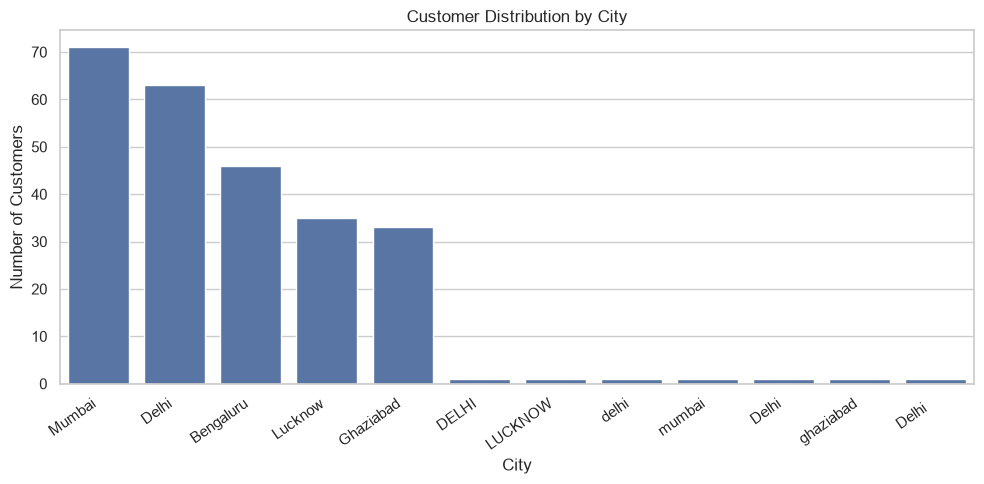

In [34]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="City", order=df["City"].value_counts().index)
plt.title("Customer Distribution by City")
plt.xlabel("City")
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "01_customer_distribution_by_city.png"), dpi=300, bbox_inches="tight")
plt.show()

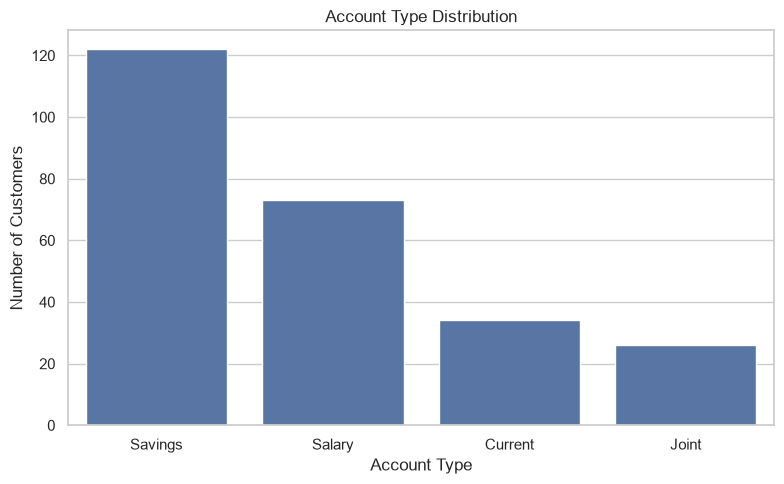

In [35]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Account_Type", order=df["Account_Type"].value_counts().index)
plt.title("Account Type Distribution")
plt.xlabel("Account Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "02_account_type_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

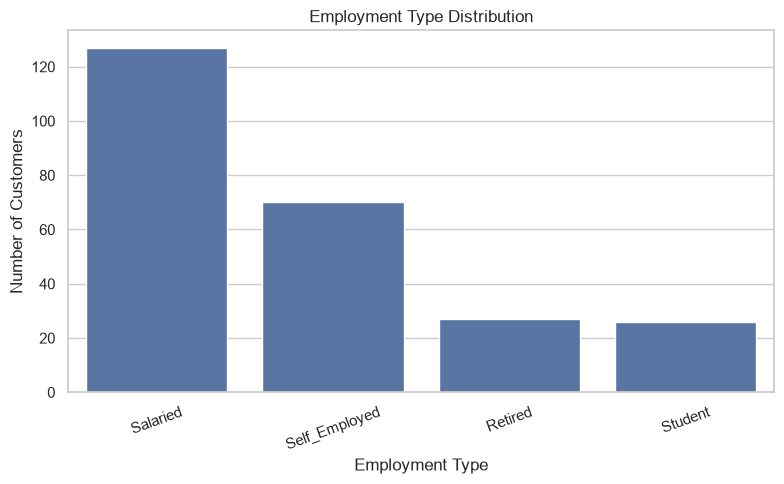

In [37]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Employment_Type", order=df["Employment_Type"].value_counts().index)
plt.title("Employment Type Distribution")
plt.xlabel("Employment Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "03_employment_type_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

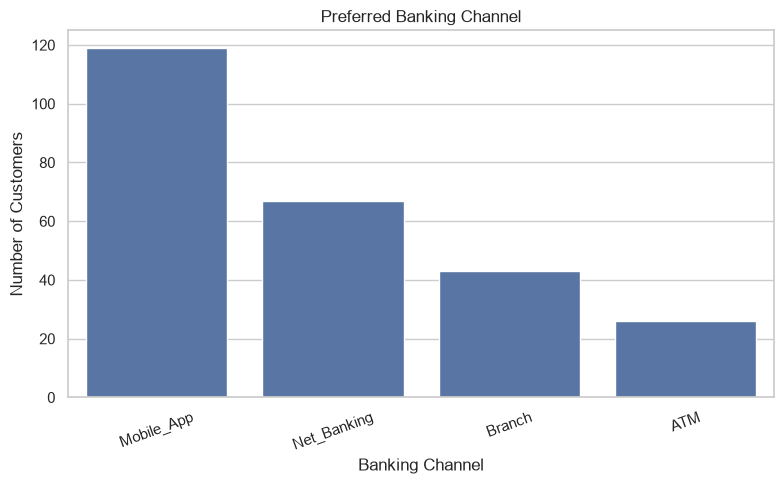

In [38]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Preferred_Channel", order=df["Preferred_Channel"].value_counts().index)
plt.title("Preferred Banking Channel")
plt.xlabel("Banking Channel")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "04_preferred_banking_channel.png"), dpi=300, bbox_inches="tight")
plt.show()

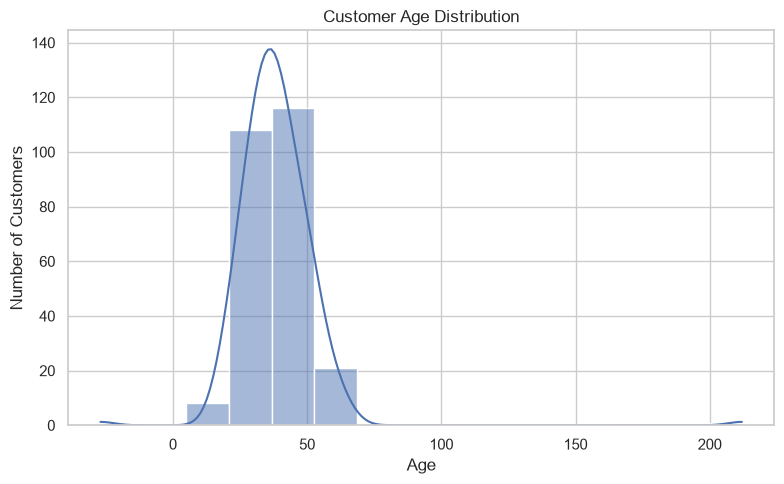

In [39]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", bins=15, kde=True)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "05_age_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

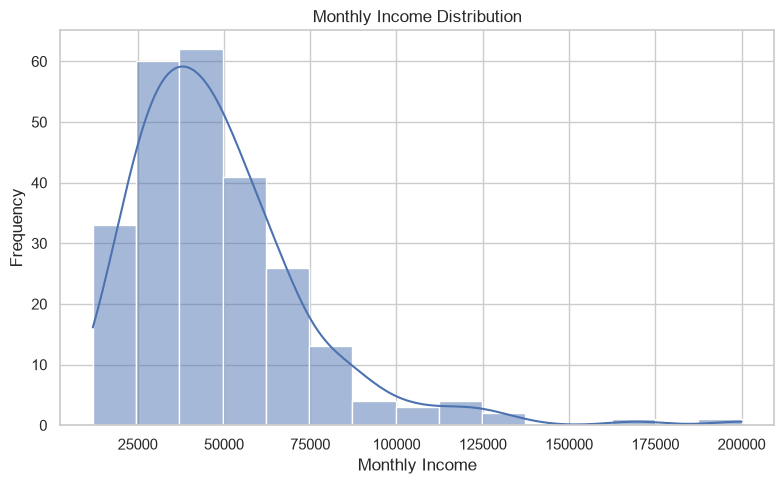

In [40]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Monthly_Income", bins=15, kde=True)
plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "06_monthly_income_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

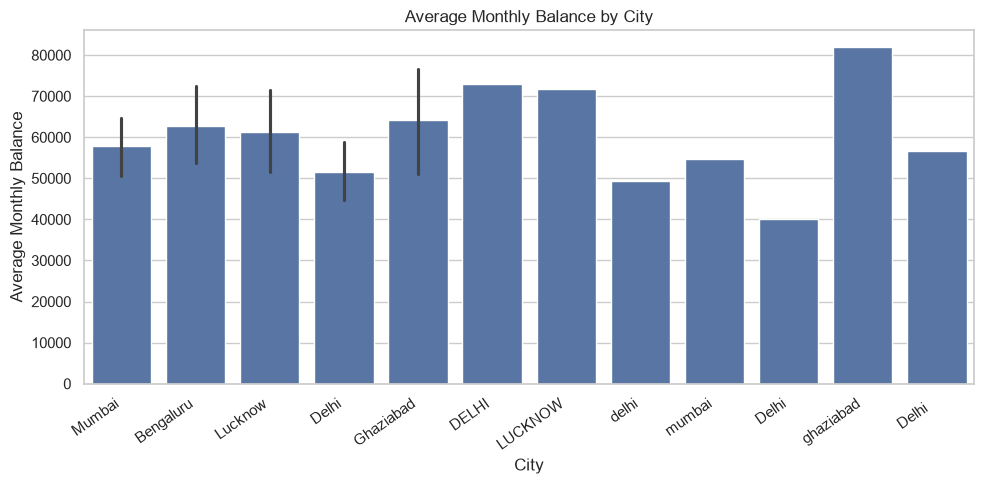

In [41]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="City", y="Avg_Monthly_Balance")
plt.title("Average Monthly Balance by City")
plt.xlabel("City")
plt.ylabel("Average Monthly Balance")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "07_average_balance_by_city.png"), dpi=300, bbox_inches="tight")
plt.show()

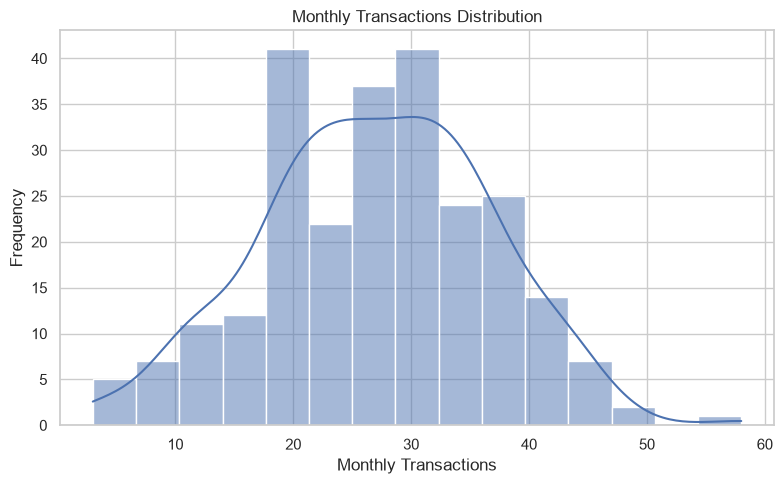

In [42]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Monthly_Transactions", bins=15, kde=True)
plt.title("Monthly Transactions Distribution")
plt.xlabel("Monthly Transactions")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "08_monthly_transactions_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

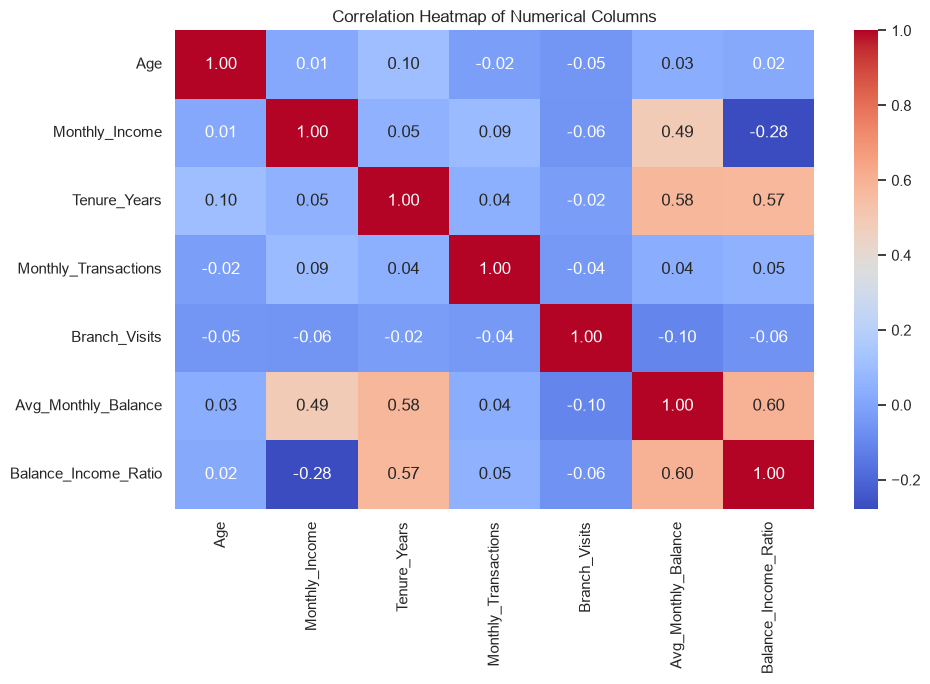

In [43]:
correlation = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Columns")
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "09_correlation_heatmap.png"), dpi=300, bbox_inches="tight")
plt.show()

In [44]:
df.nlargest(10, "Avg_Monthly_Balance")[
    ["Customer_ID", "City", "Account_Type", "Monthly_Income", "Avg_Monthly_Balance"]
]

,Customer_ID,City,Account_Type,Monthly_Income,Avg_Monthly_Balance
109,C1111,Delhi,Current,62000.0,153800
64,C1018,Mumbai,Joint,60000.0,147900
36,C1199,Ghaziabad,Savings,125500.0,146100
159,C1156,Lucknow,Savings,70000.0,145200
164,C1194,Bengaluru,Current,200000.0,145100
33,C1075,Ghaziabad,Current,69000.0,138900
71,C1115,Lucknow,Current,46500.0,124900
69,C1012,Ghaziabad,Salary,42000.0,122900
81,C1122,Lucknow,Savings,85500.0,120500
248,C1229,Ghaziabad,Savings,67000.0,117200


In [45]:
df.nlargest(10, "Monthly_Transactions")[
    ["Customer_ID", "City", "Preferred_Channel", "Monthly_Transactions"]
]

,Customer_ID,City,Preferred_Channel,Monthly_Transactions
113,C1151,Delhi,Mobile_App,58.0
37,C1176,Bengaluru,Branch,48.0
68,C1024,Bengaluru,Mobile_App,47.0
172,C1167,Lucknow,Mobile_App,45.0
66,C1180,Bengaluru,Net_Banking,44.0
90,C1180,Bengaluru,Net_Banking,44.0
92,C1116,Delhi,Mobile_App,44.0
93,C1171,Ghaziabad,Net_Banking,44.0
114,C1242,Ghaziabad,Mobile_App,44.0
164,C1194,Bengaluru,Mobile_App,44.0


In [46]:
print("Total customers:", len(df))
print("Total cities:", df["City"].nunique())
print("Account types:", df["Account_Type"].nunique())
print("Employment types:", df["Employment_Type"].nunique())
print("Preferred banking channels:", df["Preferred_Channel"].nunique())
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate records:", df.duplicated().sum())

Total customers: 255
Total cities: 12
Account types: 4
Employment types: 4
Preferred banking channels: 4
Total missing values: 39
Total duplicate records: 5


In [47]:
# Save cleaned dataset

df.to_csv("../data/processed/bank_data_cleaned.csv", index=False)

print("Cleaned CSV file saved successfully!")

Cleaned CSV file saved successfully!
